# Imbalanced Data

## 1. What Is Imbalanced Data?

Imbalanced data occurs when the target classes in a classification dataset have significantly different numbers of observations.

In other words, one class contains many more observations than another class.

**Example:**

Suppose a bank has 1,000 transactions:

* 980 legitimate transactions
* 20 fraudulent transactions

Here, legitimate transactions represent 98% of the dataset, while fraudulent transactions represent only 2%.

This is an imbalanced classification dataset because the two classes are not equally represented.

## 2. What Is a Class?

A class is one of the possible categories that a classification model predicts.

Examples:

* Fraud / Not Fraud
* Churn / No Churn
* Disease / No Disease
* Spam / Not Spam
* Defective / Non-Defective

In binary classification, there are two classes.

In multiclass classification, there are more than two classes.

## 3. What Are the Majority and Minority Classes?

**Majority Class:**

The class containing more observations.

**Minority Class:**

The class containing fewer observations.

Example:

| Transaction Type | Number of Transactions |
| ---------------- | ---------------------: |
| Legitimate       |                    980 |
| Fraudulent       |                     20 |

* Majority class: Legitimate
* Minority class: Fraudulent

The minority class may be more important to detect, even though it contains fewer observations.

## 4. Why Is Imbalanced Data a Problem?

Imbalanced data can make it difficult for a machine learning model to learn patterns from the minority class.

A model may predict the majority class for most observations and still achieve high accuracy.

For example, if 98% of transactions are legitimate, a model that predicts every transaction as legitimate achieves 98% accuracy.

However, it detects none of the fraudulent transactions.

This means that accuracy alone can give a misleading impression of model performance.

**Important:** Imbalanced data does not always cause poor model performance, but it requires careful evaluation.

## 5. What Is Class Distribution?

Class distribution describes how many observations belong to each target class.

We can inspect class distribution using:

```python
df["Target"].value_counts()
```

To calculate class proportions:

```python
df["Target"].value_counts(normalize=True) * 100
```

This helps us understand whether the dataset is balanced or imbalanced.

## 6. What Is Accuracy?

Accuracy measures the proportion of predictions that are correct.

Formula:

Accuracy = (Correct Predictions / Total Predictions)

For example, if a model correctly predicts 90 out of 100 observations:

Accuracy = 90 / 100 = 90%

Accuracy is useful, but it may not be sufficient for imbalanced classification.

## 7. What Is Precision?

Precision measures how many observations predicted as positive are actually positive.

Formula:

Precision = TP / (TP + FP)

Where:

* TP = True Positives
* FP = False Positives

**Example:**

A fraud detection model identifies 10 transactions as fraudulent. Seven are genuinely fraudulent.

Precision = 7 / 10 = 70%

High precision means fewer false alarms among the observations predicted as positive.

## 8. What Is Recall?

Recall measures how many actual positive observations the model correctly identifies.

Formula:

Recall = TP / (TP + FN)

Where:

* TP = True Positives
* FN = False Negatives

**Example:**

There are 20 fraudulent transactions, and the model detects 15.

Recall = 15 / 20 = 75%

High recall means the model identifies a larger proportion of the actual positive cases.

Recall is especially important when missing a positive case has a high cost.

## 9. What Is the F1-Score?

The F1-score is the harmonic mean of precision and recall.

Formula:

F1 = 2 × (Precision × Recall) / (Precision + Recall)

It combines precision and recall into a single metric.

F1-score is useful when we want to balance false positives and false negatives.

However, it does not account for true negatives and does not directly represent the financial or operational cost of errors.

## 10. What Is a Confusion Matrix?

A confusion matrix summarizes a classification model's predictions against the actual classes.

For binary classification:

|                 |  Predicted Positive |  Predicted Negative |
| --------------- | ------------------: | ------------------: |
| Actual Positive |  True Positive (TP) | False Negative (FN) |
| Actual Negative | False Positive (FP) |  True Negative (TN) |

Definitions:

* **True Positive:** The model correctly predicts a positive case.
* **True Negative:** The model correctly predicts a negative case.
* **False Positive:** The model predicts positive, but the actual class is negative.
* **False Negative:** The model predicts negative, but the actual class is positive.

A confusion matrix helps us understand the types of mistakes a model makes.

## 11. What Is Random Oversampling?

Random oversampling increases the number of minority-class training observations by duplicating existing minority-class examples.

Example:

Before oversampling:

* Majority class: 900 observations
* Minority class: 100 observations

After oversampling:

* Majority class: 900 observations
* Minority class: 900 observations

Oversampling makes the class counts equal in this example.

### Advantages

* Simple to implement.
* Does not discard majority-class observations.
* Can help a model learn from the minority class.

### Limitations

* Duplicates existing observations.
* Can increase overfitting.
* Increases the size of the training dataset.

## 12. What Is Random Undersampling?

Random undersampling reduces the number of majority-class observations by removing selected examples.

Example:

Before undersampling:

* Majority class: 900 observations
* Minority class: 100 observations

After undersampling:

* Majority class: 100 observations
* Minority class: 100 observations

### Advantages

* Reduces training-data size.
* Can reduce training time.
* May help when the majority class is extremely large.

### Limitations

* Removes potentially useful observations.
* May discard important patterns from the majority class.
* Can reduce model performance if too much information is lost.

## 13. What Is SMOTE?

SMOTE stands for Synthetic Minority Over-sampling Technique.

It creates synthetic minority-class observations by interpolating between existing minority-class examples and their neighbors.

Unlike random oversampling, which duplicates observations, SMOTE generates new feature vectors.

### Advantages

* Increases minority-class representation.
* Can help some models learn minority-class patterns.
* Does not simply duplicate every added observation.

### Limitations

* Synthetic examples may not represent realistic observations.
* It can increase overlap between classes.
* It may be inappropriate for some categorical or structured datasets without suitable adaptations.
* It does not guarantee improved model performance.

## 14. What Is Class Weighting?

Class weighting assigns different importance to different classes during model training.

For example, a model can assign a higher penalty to mistakes involving the minority class.

In scikit-learn, some classifiers support:

```python
class_weight="balanced"
```

The model adjusts class weights based on the class frequencies in the training data.

### Advantages

* Does not require creating synthetic observations.
* Does not require discarding majority-class observations.
* Can be effective for many classification problems.

### Limitations

* Not supported by every algorithm.
* Can increase false positives if the model becomes more sensitive to the minority class.
* Requires evaluation to determine whether it helps.

## 15. Comparison of Imbalanced Data Techniques

| Technique            | How It Works                              | Main Risk                      |
| -------------------- | ----------------------------------------- | ------------------------------ |
| Random Oversampling  | Duplicates minority-class observations    | Overfitting                    |
| Random Undersampling | Removes majority-class observations       | Information loss               |
| SMOTE                | Creates synthetic minority examples       | Unrealistic synthetic examples |
| Class Weighting      | Changes the cost of classification errors | May increase false positives   |

No single technique is best for every dataset.

## 16. When Should We Use Each Technique?

**Random Oversampling:**

Consider it when minority-class representation is low and retaining all majority-class observations is important.

**Random Undersampling:**

Consider it when the majority class is very large and reducing training time is important.

**SMOTE:**

Consider it for suitable numerical feature datasets when synthetic minority examples are meaningful.

**Class Weighting:**

Consider it when the algorithm supports class weights and you want to emphasize minority-class mistakes without changing the training sample counts.

Always compare techniques using appropriate validation metrics.

## 17. Preventing Data Leakage During Resampling

Resampling must be applied only to training data.

Correct workflow:

1. Separate features and target.
2. Split the dataset into training and testing sets.
3. Apply oversampling, undersampling, or SMOTE only to the training data.
4. Train the model using the resampled training data.
5. Evaluate on the original, untouched test data.

**Never resample the entire dataset before splitting it.**

Doing so can allow information from the test set to influence the training process and produce misleading evaluation results.

For cross-validation, resampling should occur separately inside each training fold, usually through an appropriate pipeline.

## 18. Choosing the Right Evaluation Metrics

For imbalanced classification, consider:

* **Precision:** How reliable are positive predictions?
* **Recall:** How many actual positive cases are detected?
* **F1-score:** What is the balance between precision and recall?
* **Confusion Matrix:** What kinds of classification errors occur?
* **PR-AUC:** Ho


# Demonstration of the Concept: Credit Card Fraud Detection

## Business Scenario

Imagine that a bank wants to build a machine learning model to detect fraudulent credit card transactions.

The dataset contains 10,000 transactions:

| Transaction Type | Number of Transactions |
| ---------------- | ---------------------: |
| Legitimate       |                  9,800 |
| Fraudulent       |                    200 |
| Total            |                 10,000 |

The majority class is legitimate transactions, while the minority class is fraudulent transactions.

Fraudulent transactions represent only 2% of the dataset.

This is an imbalanced classification problem.

## Problem Identification

Suppose a model predicts every transaction as legitimate.

It correctly predicts all 9,800 legitimate transactions but misses all 200 fraudulent transactions.

Its accuracy is:

Accuracy = 9,800 / 10,000 = 98%

At first glance, 98% accuracy looks excellent.

However, the model detects zero fraudulent transactions.

This demonstrates why accuracy alone is not sufficient for evaluating imbalanced classification.

## Understanding the Evaluation Metrics

Suppose another model produces these results:

* True Positives (TP): 150
* False Positives (FP): 50
* True Negatives (TN): 9,750
* False Negatives (FN): 50

### Accuracy

Accuracy = (TP + TN) / Total

Accuracy = (150 + 9,750) / 10,000 = 99%

### Precision

Precision = TP / (TP + FP)

Precision = 150 / (150 + 50) = 75%

This means 75% of the transactions predicted as fraudulent were actually fraudulent.

### Recall

Recall = TP / (TP + FN)

Recall = 150 / (150 + 50) = 75%

This means the model detected 75% of the actual fraudulent transactions.

### F1-Score

F1 = 2 × (Precision × Recall) / (Precision + Recall)

F1 = 2 × (0.75 × 0.75) / (0.75 + 0.75) = 0.75

The F1-score is 75%.

## Applying Imbalanced Data Techniques

### 1. Random Oversampling

Increase the number of fraudulent observations in the training data by duplicating minority-class examples.

This may help the model learn more about fraud, but repeated observations can increase overfitting.

### 2. Random Undersampling

Reduce the number of legitimate observations in the training data.

This can reduce training time, but removing too many legitimate transactions may cause the model to miss important patterns.

### 3. SMOTE

Create synthetic fraudulent observations from existing minority-class examples and their neighbors.

SMOTE may be useful for suitable numerical features, but generated examples must be evaluated carefully.

### 4. Class Weighting

Assign a higher penalty to incorrectly classifying fraudulent transactions.

This can encourage the model to pay more attention to the minority class without duplicating or removing observations.

## Expected Observation

After applying a suitable technique, the model may detect more fraudulent transactions.

However, detecting more fraud can also increase false positives.

Therefore, compare precision, recall, F1-score, and the confusion matrix rather than choosing a model based only on accuracy.

## AI/ML Application

Imbalanced classification is common in:

* Credit card fraud detection
* Medical diagnosis
* Customer churn prediction
* Manufacturing defect detection
* Cybersecurity threat detection
* Insurance claim fraud detection

## Important Learning Point

**The goal is not simply to make the class counts equal. The goal is to build a model that performs well on the real problem.**

Choose a resampling or class-weighting technique based on the data, business requirements, and evaluation results. Keep the test set untouched so it reflects the original class distribution.


Dataset Sample:
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6  Fraud
0  -1.101699  -0.734518   0.108393  -0.189459  -0.559962   0.847294      0
1   1.237495  -0.523637  -0.235316  -1.132829  -0.945952   0.573169      0
2  -0.829820  -0.182240   0.520623   0.174152  -0.034772   0.346180      0
3  -1.352138  -0.721564  -0.279812  -0.895505  -1.110221   1.257867      0
4  -1.092563  -0.730788  -0.636699  -1.333284  -1.342253   0.196545      0

Class Counts:
Fraud
0    1893
1     107
Name: count, dtype: int64

Class Percentages:
Fraud
0    94.65
1     5.35
Name: proportion, dtype: float64


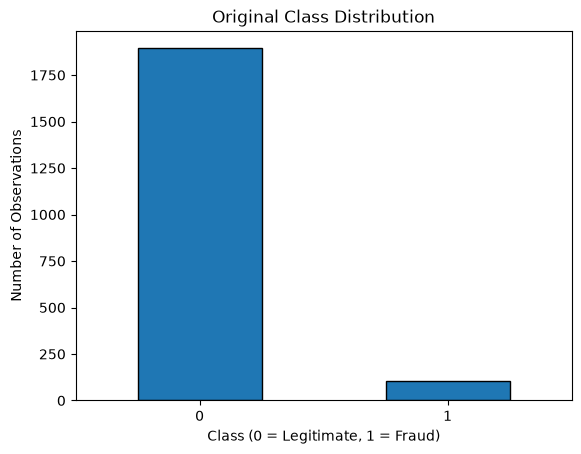


Training Class Distribution:
Fraud
0    1420
1      80
Name: count, dtype: int64

Testing Class Distribution:
Fraud
0    473
1     27
Name: count, dtype: int64

Baseline Logistic Regression
Accuracy: 0.946
Precision: 0.0
Recall: 0.0
F1-Score: 0.0

Confusion Matrix:
[[473   0]
 [ 27   0]]

Logistic Regression with Balanced Class Weights
Accuracy: 0.664
Precision: 0.0971
Recall: 0.6296
F1-Score: 0.1683

Confusion Matrix:
[[315 158]
 [ 10  17]]

Class Distribution After Random Oversampling:
Fraud
0    1420
1    1420
Name: count, dtype: int64

Logistic Regression with Random Oversampling
Accuracy: 0.672
Precision: 0.0994
Recall: 0.6296
F1-Score: 0.1717

Confusion Matrix:
[[319 154]
 [ 10  17]]

Model Comparison:
              Model  Accuracy  Precision  Recall  F1_Score
           Baseline     0.946     0.0000  0.0000    0.0000
     Class Weighted     0.664     0.0971  0.6296    0.1683
Random Oversampling     0.672     0.0994  0.6296    0.1717

Important Learning Points:
1. Check class di

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample

# --------------------------------------------------
# 1. Create an Imbalanced Dataset
# --------------------------------------------------

X, y = make_classification(
    n_samples=2000,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_classes=2,
    weights=[0.95, 0.05],
    random_state=42
)

feature_names = [
    "Feature_1",
    "Feature_2",
    "Feature_3",
    "Feature_4",
    "Feature_5",
    "Feature_6"
]

df = pd.DataFrame(X, columns=feature_names)
df["Fraud"] = y

print("Dataset Sample:")
print(df.head())

# --------------------------------------------------
# 2. Check Class Distribution
# --------------------------------------------------

print("\nClass Counts:")
print(df["Fraud"].value_counts())

print("\nClass Percentages:")
print((df["Fraud"].value_counts(normalize=True) * 100).round(2))

# Visualize the original class distribution.
df["Fraud"].value_counts().sort_index().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Original Class Distribution")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

# --------------------------------------------------
# 3. Split Data Before Resampling
# --------------------------------------------------

X = df[feature_names]
y = df["Fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

# --------------------------------------------------
# 4. Create a Function to Evaluate a Model
# --------------------------------------------------

def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)

    print(f"\n{'=' * 50}")
    print(model_name)
    print("=" * 50)

    print("Accuracy:", round(
        accuracy_score(y_test, predictions), 4
    ))

    print("Precision:", round(
        precision_score(y_test, predictions, zero_division=0), 4
    ))

    print("Recall:", round(
        recall_score(y_test, predictions, zero_division=0), 4
    ))

    print("F1-Score:", round(
        f1_score(y_test, predictions, zero_division=0), 4
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    return predictions

# --------------------------------------------------
# 5. Baseline Model
# --------------------------------------------------

baseline_model = LogisticRegression(max_iter=1000)

baseline_model.fit(X_train, y_train)

baseline_predictions = evaluate_model(
    baseline_model,
    X_test,
    y_test,
    "Baseline Logistic Regression"
)

# --------------------------------------------------
# 6. Class Weighting
# --------------------------------------------------

weighted_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

weighted_model.fit(X_train, y_train)

weighted_predictions = evaluate_model(
    weighted_model,
    X_test,
    y_test,
    "Logistic Regression with Balanced Class Weights"
)

# --------------------------------------------------
# 7. Random Oversampling of Training Data
# --------------------------------------------------

training_data = X_train.copy()
training_data["Fraud"] = y_train

majority_class = training_data[
    training_data["Fraud"] == 0
]

minority_class = training_data[
    training_data["Fraud"] == 1
]

minority_oversampled = resample(
    minority_class,
    replace=True,
    n_samples=len(majority_class),
    random_state=42
)

oversampled_data = pd.concat(
    [majority_class, minority_oversampled]
)

X_train_over = oversampled_data[feature_names]
y_train_over = oversampled_data["Fraud"]

print("\nClass Distribution After Random Oversampling:")
print(y_train_over.value_counts())

oversampled_model = LogisticRegression(max_iter=1000)

oversampled_model.fit(X_train_over, y_train_over)

oversampled_predictions = evaluate_model(
    oversampled_model,
    X_test,
    y_test,
    "Logistic Regression with Random Oversampling"
)

# --------------------------------------------------
# 8. Compare Evaluation Metrics
# --------------------------------------------------

results = []

models = {
    "Baseline": baseline_model,
    "Class Weighted": weighted_model,
    "Random Oversampling": oversampled_model
}

for model_name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))

# --------------------------------------------------
# 9. Important Learning Points
# --------------------------------------------------

print("\nImportant Learning Points:")
print("1. Check class distribution before training.")
print("2. Accuracy alone may be misleading.")
print("3. Precision measures positive prediction reliability.")
print("4. Recall measures the proportion of positives detected.")
print("5. F1-score combines precision and recall.")
print("6. Oversampling is applied only to training data.")
print("7. The test data remains unchanged.")
print("8. Compare techniques using suitable metrics.")